# Analysis

Reads everything from `result/`. Figures are written to `result/figures/`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from vitcnn import analysis as A, plots as P

RESULT = ROOT / "result"
pd.set_option("display.width", 200)

## Sanity checks

In [2]:
sanity = json.loads((RESULT / "sanity" / "sanity.json").read_text())
print(json.dumps(sanity["splits"]["subsets"]["seed1"], indent=1))
print("10% overlap seed1 vs seed2:", sanity["splits"]["subset_10%_overlap_seed1_vs_seed2"])
pd.DataFrame(sanity["overfit_tiny"]).T

{
 "sizes": {
  "10%": 4500,
  "30%": 13500,
  "100%": 45000
 },
 "per_class_10%": [
  450,
  450,
  450,
  450,
  450,
  450,
  450,
  450,
  450,
  450
 ],
 "nested_10_in_30": true,
 "nested_30_in_100": true,
 "no_overlap_with_val": true
}
10% overlap seed1 vs seed2: 444


,loss_first,loss_last,train_acc_end,passed,seconds
vit_p4,2.41643,0.210452,0.914062,False,3.590266
vit_p8,2.369341,0.00485,1.0,True,3.438499
resnet18_w05,2.383845,0.000363,1.0,True,5.735285


In [3]:
for p in sorted((RESULT / "sanity").glob("overfit_*steps.json")):
    print(p.name)
    display(pd.DataFrame(json.loads(p.read_text())).T)

overfit_1500steps.json


,loss_first,loss_last,train_acc_end,passed,seconds
vit_p4,2.41643,0.000248,1.0,True,17.250207
vit_p8,2.369341,0.000218,1.0,True,16.008167
resnet18_w05,2.383845,0.000033,1.0,True,16.225563


## Throughput

In [4]:
bench = json.loads((RESULT / "bench" / "bench.json").read_text())
display(pd.DataFrame(bench["results"])[["model", "aug", "n_params", "steps_per_s", "train_img_per_s", "infer_img_per_s", "peak_mem_mb"]].round(1))
bench["estimated_gpu_hours"]

,model,aug,n_params,steps_per_s,train_img_per_s,infer_img_per_s,peak_mem_mb
0,vit_p4,basic,2693578,52.6,6728.7,27547.6,595.6
1,vit_p4,strong,2693578,51.1,6536.8,26656.7,596.2
2,vit_p8,basic,2712010,57.7,7391.1,118385.4,333.3
3,vit_p8,strong,2712010,51.6,6599.0,117657.0,333.4
4,resnet18_w05,basic,2797610,61.0,7801.6,34402.5,432.5
5,resnet18_w05,strong,2797610,56.5,7234.4,34089.1,426.8


{'lr_sweep': 0.33,
 'pilot10': 0.64,
 'tier1': 3.82,
 'tier2': 1.02,
 'tier3': 1.91,
 'total': 7.71}

## LR sweep

,model,lr,epochs,best_step,val_acc_best,val_acc_final
0,resnet18_w05,0.0005,28.4,8000,0.8698,0.8698
1,resnet18_w05,0.0010,28.4,10000,0.8916,0.8916
2,resnet18_w05,0.0020,28.4,9000,0.9048,0.9048
3,resnet18_w05,0.0040,28.4,10000,0.9102,0.9102
4,vit_p4,0.0005,28.4,10000,0.7358,0.7358
5,vit_p4,0.0010,28.4,10000,0.7438,0.7438
6,vit_p4,0.0020,28.4,9500,0.5488,0.5488


{'vit_p4': 0.001, 'resnet18_w05': 0.004}


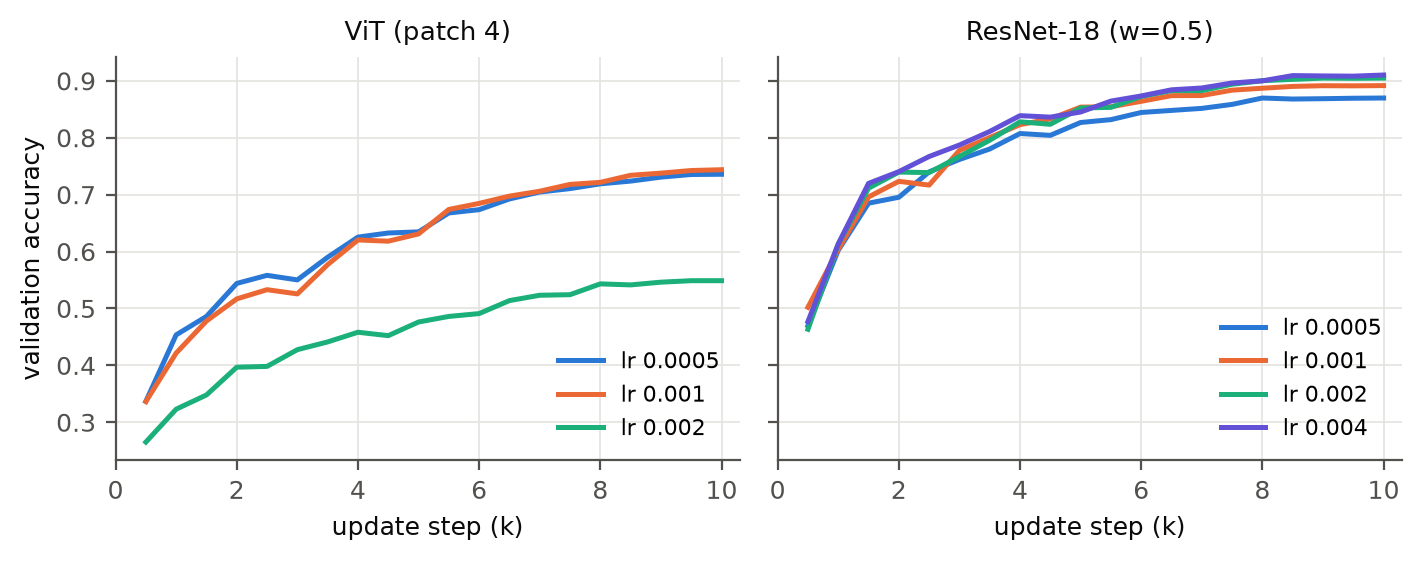

In [5]:
sweep = A.load_runs(RESULT, plan="lr_sweep")
display(A.run_table(sweep)[["model", "lr", "epochs", "best_step", "val_acc_best", "val_acc_final"]])
print(json.loads((RESULT / "chosen_lr.json").read_text())["chosen_lr"])
display(Image(filename=str(P.plot_lr_sweep(RESULT))))

## Pilot: 10% of the data, seed 0, validation only

,model,aug,epochs,best_step,val_acc_best,val_acc_final,val_loss_min,val_loss_min_step,val_loss_final,train_loss_final
0,resnet18_w05,basic,853.3,28500,0.8138,0.8124,1.179723,3000,1.397246,0.000047
1,resnet18_w05,strong,853.3,28500,0.8692,0.8640,0.481343,28500,0.511773,0.935801
2,vit_p4,basic,853.3,21000,0.5850,0.5844,1.315563,1500,3.276526,0.000005
3,vit_p4,strong,853.3,30000,0.7406,0.7406,0.828924,30000,0.828924,0.914900


{'gap_basic': 22.88, 'gap_strong': 12.86, 'G_vit': 15.56, 'G_resnet': 5.54, 'G_vit_minus_G_resnet': 10.02}


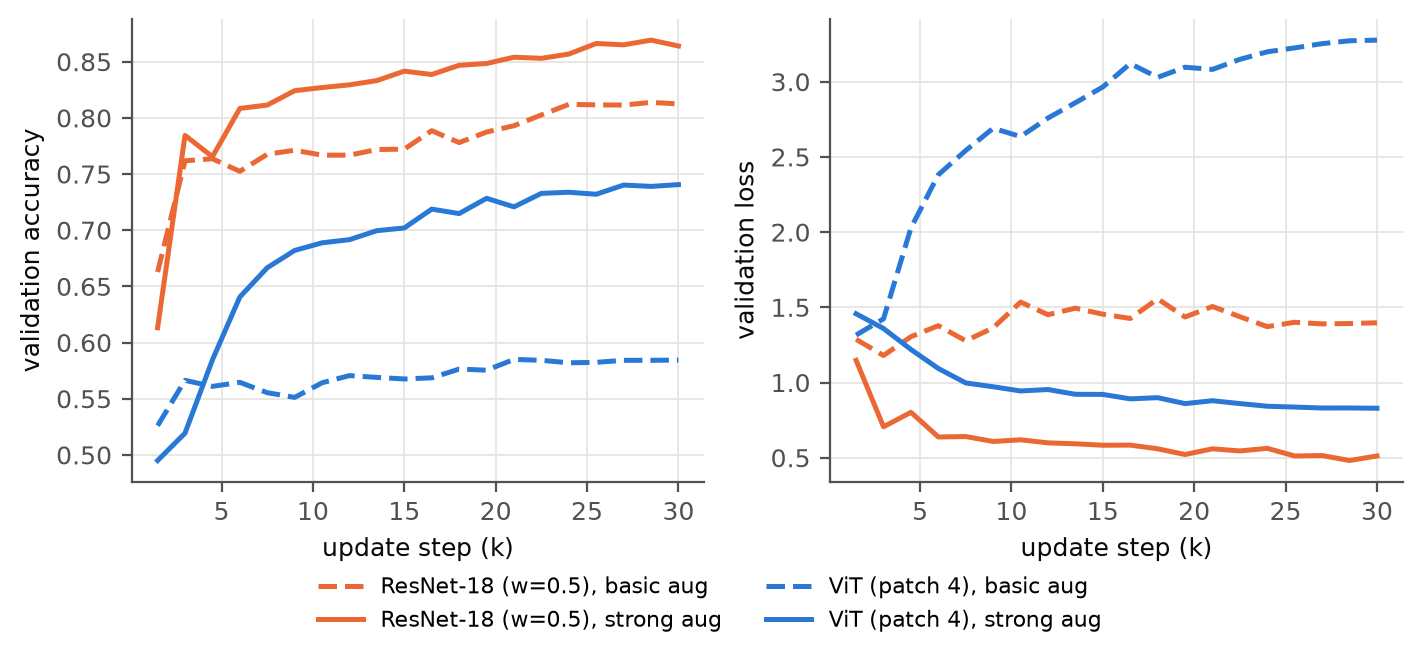

In [6]:
pilot = A.load_runs(RESULT, plan="pilot10")
display(A.run_table(pilot)[["model", "aug", "epochs", "best_step", "val_acc_best", "val_acc_final",
                            "val_loss_min", "val_loss_min_step", "val_loss_final", "train_loss_final"]])
print({k: round(100 * v, 2) for k, v in A.aug_gaps(pilot).items()})  # accuracy points
display(Image(filename=str(P.plot_curves(RESULT, plan="pilot10"))))

,model,aug,actual_s,expected_s,ratio
0,resnet18_w05,basic,478.11,492.21,0.97
1,resnet18_w05,strong,522.99,530.80,0.99
2,vit_p4,basic,540.36,570.69,0.95
3,vit_p4,strong,598.27,587.44,1.02


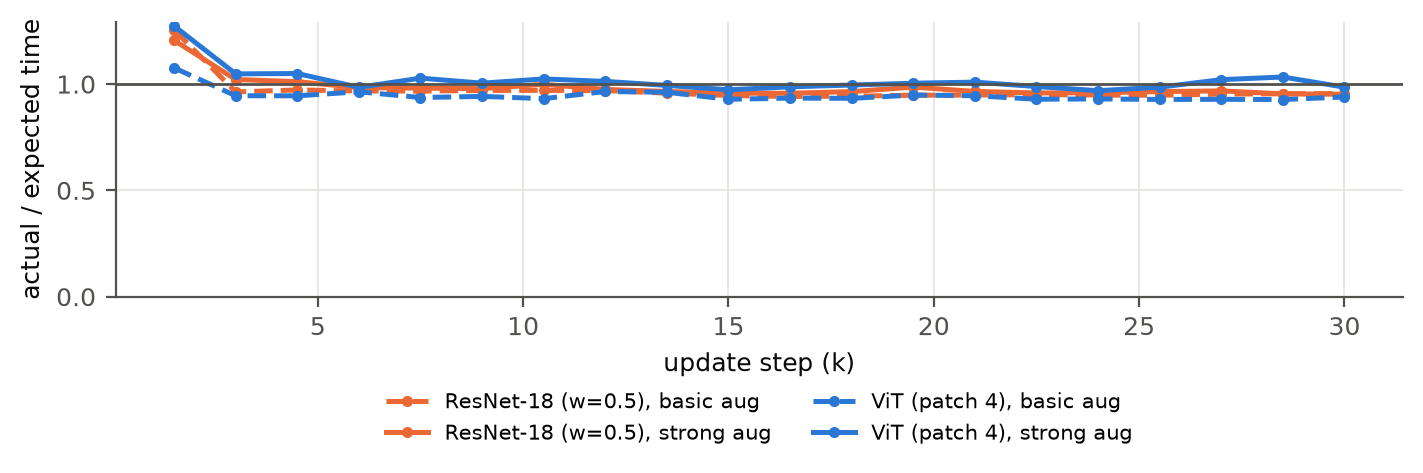

In [7]:
# runs got slower in the middle of the pilot queue, compare with the bench estimate
display(A.timing_vs_bench(pilot, bench).round(2))
display(Image(filename=str(P.plot_timing(RESULT, plan="pilot10"))))

## Example images

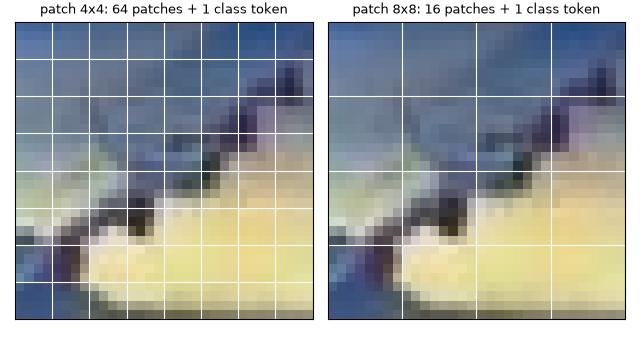

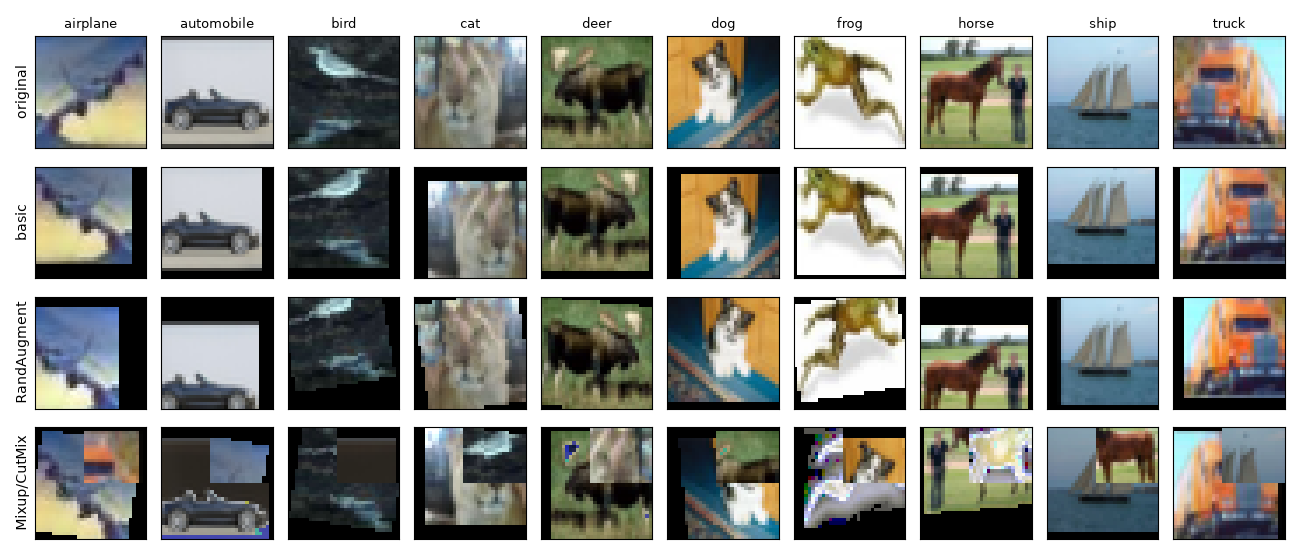

In [8]:
display(Image(filename=str(P.plot_patch_grid(ROOT / "data", RESULT))))
display(Image(filename=str(P.plot_aug_examples(ROOT / "data", RESULT))))

## Main runs

In [9]:
# TODO: tier1 aggregation once the runs finish
# - mean/std over seeds per (model, frac, aug)
# - paired differences D_m, G_m per seed, sign consistency
# - McNemar per seed on result/runs/main__*/test_preds.npy